# NHANES: does disrupted sleep go with lower cognition?

SteadyState rests on one premise: **poor sleep lowers cognitive performance in older adults**.
If that is not true, sleep cannot be used to explain away a drop in speech scores.

This notebook tests it on NHANES 2011–2014 (adults 60+, 7 days of wrist data, 4 cognitive tests).

**Input:** `data/processed/nhanes/nhanes_participants.csv` (from `src/preprocessing/nhanes.py`)

**Questions**
1. Is average sleep duration associated with cognition after adjusting for age, sex, education, race and income?
2. Is **night-to-night variability** in sleep (`sleep_h_sd`) associated with cognition? This is the "state" signal the project relies on.
3. Is sleep **timing** irregularity (`midpoint_h_sd`) associated with cognition?
4. Which cognitive tests drive the association?

All results are **associations, not causes**: cognition was measured once.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# Find the repo root whether the notebook is run from notebooks/ or the root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/"data"/"processed").exists())
participants = pd.read_csv(ROOT/"data"/"processed"/"nhanes"/"nhanes_participants.csv")
participants.shape

(2853, 36)

## 1. Analysis sample

Keep people with all four cognitive tests and every covariate. Dropping rows with missing covariates
(mostly income) keeps every model on the same people, so their results are comparable.

In [2]:
SLEEP = ["sleep_h_mean", "sleep_h_sd", "midpoint_h_sd"]
COVARIATES = ["age", "female", "education", "race_eth", "income_poverty_ratio", "n_valid_nights"]
TESTS = ["cerad_immediate", "cerad_delayed", "animal_fluency", "digit_symbol"]

d = participants[participants["cog_complete"]==1].dropna(subset=SLEEP+COVARIATES).copy()
print(f"Analysis sample: {len(d):,} of {len(participants):,} participants")

Analysis sample: 2,282 of 2,853 participants


In [3]:
d[["age", "female", "education", "income_poverty_ratio", "self_report_sleep_h",
   "sleep_h_mean", "sleep_h_sd", "midpoint_h_sd", "n_valid_nights", *TESTS]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,2282.0,69.62,6.76,60.00,64.00,69.00,76.00,80.00
female,2282.0,0.52,0.50,0.00,0.00,1.00,1.00,1.00
education,2282.0,3.41,1.26,1.00,3.00,4.00,4.00,5.00
income_poverty_ratio,2282.0,2.58,1.58,0.00,1.19,2.14,4.08,5.00
self_report_sleep_h,2277.0,7.02,1.44,2.00,6.00,7.00,8.00,12.00
sleep_h_mean,2282.0,8.44,1.63,4.00,7.33,8.26,9.37,14.89
sleep_h_sd,2282.0,1.44,0.64,0.17,0.99,1.34,1.78,5.46
midpoint_h_sd,2282.0,1.08,0.51,0.12,0.73,0.98,1.33,5.78
n_valid_nights,2282.0,6.90,0.92,4.00,6.00,7.00,8.00,8.00
cerad_immediate,2282.0,18.93,4.68,0.00,16.00,19.00,22.00,30.00


## 2. Standardise sleep measures

Each sleep measure is converted to a z-score, so every coefficient below reads the same way:
**change in cognition (in SD units) per 1 SD more of that sleep measure.**

In [4]:
for c in SLEEP:
    d[f"{c}_z"] = (d[c]-d[c].mean())/d[c].std()

ADJ = "age + female + C(education) + C(race_eth) + income_poverty_ratio + n_valid_nights"
SLEEP_TERMS = "sleep_h_mean_z + sleep_h_sd_z + midpoint_h_sd_z"

In [5]:
def sleep_table(model):
    ci = model.conf_int()
    keep = [k for k in model.params.index if "sleep" in k or "midpoint" in k]
    return pd.DataFrame({
        "coef": model.params[keep],
        "ci_low": ci.loc[keep,0],
        "ci_high": ci.loc[keep, 1],
        "p": model.pvalues[keep],
    }).round(4)

def fit(formula, data=d, **kw):
    return smf.ols(formula, data).fit(cov_type="HC3", **kw)


## 3. Composite cognition models

In [7]:
m0 = fit(f"cog_composite_z ~ {SLEEP_TERMS}")
print(f"M0 unadjusted R^2 = {m0.rsquared:.3f}")
sleep_table(m0)

M0 unadjusted R^2 = 0.024


,coef,ci_low,ci_high,p
sleep_h_mean_z,-0.1095,-0.1430,-0.0760,0.0000
sleep_h_sd_z,-0.0497,-0.0871,-0.0123,0.0091
midpoint_h_sd_z,0.0101,-0.0260,0.0462,0.5832


In [6]:
m1 = fit(f"cog_composite_z ~ {SLEEP_TERMS} + {ADJ}")
print(f"M1 adjusted R^2 = {m1.rsquared:.3f}")
sleep_table(m1)

M1 adjusted R^2 = 0.394


,coef,ci_low,ci_high,p
sleep_h_mean_z,-0.0599,-0.0892,-0.0306,0.0001
sleep_h_sd_z,-0.0370,-0.0675,-0.0065,0.0175
midpoint_h_sd_z,0.0166,-0.0121,0.0452,0.2571


**M2** adds a squared term for sleep duration. In older adults both very short and very long sleep
are linked to worse cognition (a U or inverted-U shape), which a straight line would miss.

In [8]:
m2 = fit(f"cog_composite_z ~ {SLEEP_TERMS} + I(sleep_h_mean_z**2) + {ADJ}")
print(f"M2 + quadratic R^2 = {m2.rsquared:.3f}")
sleep_table(m2)

M2 + quadratic R^2 = 0.394


,coef,ci_low,ci_high,p
sleep_h_mean_z,-0.0501,-0.0807,-0.0195,0.0013
sleep_h_sd_z,-0.0386,-0.0692,-0.0080,0.0134
midpoint_h_sd_z,0.0180,-0.0109,0.0469,0.2217
I(sleep_h_mean_z ** 2),-0.0151,-0.0345,0.0042,0.1258


## 4. Which tests drive it?

In [9]:
rows = []
for t in TESTS:
    m = fit(f"{t}_z ~ {SLEEP_TERMS} + I(sleep_h_mean_z**2) + {ADJ}")
    tab = sleep_table(m)
    tab.insert(0, "test", t)
    rows.append(tab)
per_test = pd.concat(rows).reset_index(names="term")
per_test.pivot(index="term", columns="test", values="coef").round(3)

test,animal_fluency,cerad_delayed,cerad_immediate,digit_symbol
term,,,,
I(sleep_h_mean_z ** 2),-0.017,-0.002,-0.012,-0.030
midpoint_h_sd_z,-0.008,0.013,0.051,0.016
sleep_h_mean_z,-0.036,-0.076,-0.054,-0.034
sleep_h_sd_z,-0.018,-0.029,-0.048,-0.059


In [11]:
per_test.pivot(index="term", columns="test", values="p").round(4)

test,animal_fluency,cerad_delayed,cerad_immediate,digit_symbol
term,,,,
I(sleep_h_mean_z ** 2),0.1826,0.8882,0.4019,0.0059
midpoint_h_sd_z,0.7136,0.5371,0.0241,0.3410
sleep_h_mean_z,0.1083,0.0009,0.0190,0.0513
sleep_h_sd_z,0.4054,0.1849,0.0362,0.0006


## 5. Sensitivity: survey weights

NHANES over-samples some groups. Re-fitting with the 4-year exam weights, and clustering standard errors
by PSU within stratum, checks the result is not an artefact of who was sampled.
This approximates (but is not identical to) full design-based survey estimation.

In [13]:
d["cluster"] = d["strata"].astype(int)*10 + d["psu"].astype(int)
mw = smf.wls(
    f"cog_composite_z ~ {SLEEP_TERMS} + I(sleep_h_mean_z**2) + {ADJ}",
    d, weights=d["wt_mec_4yr"],
).fit(cov_type="cluster", cov_kwds={"groups": d["cluster"]})
sleep_table(mw)

,coef,ci_low,ci_high,p
sleep_h_mean_z,-0.0462,-0.0966,0.0041,0.0720
sleep_h_sd_z,-0.0580,-0.0953,-0.0208,0.0023
midpoint_h_sd_z,0.0161,-0.0249,0.0571,0.4423
I(sleep_h_mean_z ** 2),-0.0261,-0.0591,0.0069,0.1217


## 6. Plots

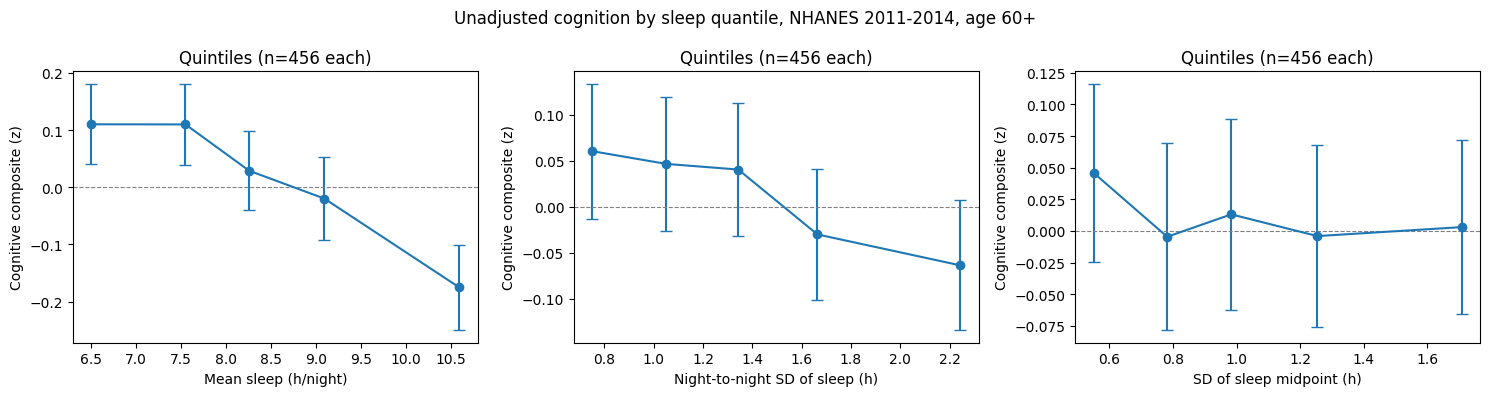

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
labels =  {"sleep_h_mean": "Mean sleep (h/night)",
            "sleep_h_sd": "Night-to-night SD of sleep (h)",
            "midpoint_h_sd": "SD of sleep midpoint (h)"}
for ax, col in zip(axes, SLEEP):
    bins = pd.qcut(d[col], 5)
    g = d.groupby(bins, observed=True)["cog_composite_z"].agg(["mean", "sem", "size"])
    x = d.groupby(bins, observed=True)[col].median()
    ax.errorbar(x, g["mean"], yerr=1.96*g["sem"], marker="o", capsize=4)
    ax.axhline(0, color="grey", lw=0.8, ls="--")
    ax.set_xlabel(labels[col])
    ax.set_ylabel("Cognitive composite (z)")
    ax.set_title(f"Quintiles (n={int(g['size'].mean())} each)")

fig.suptitle("Unadjusted cognition by sleep quantile, NHANES 2011-2014, age 60+")
fig.tight_layout()
plt.show()

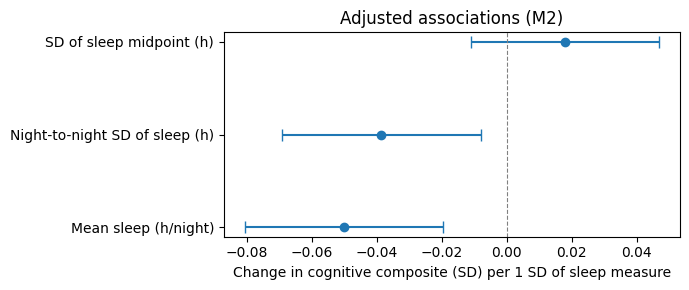

In [17]:
tab = sleep_table(m2).drop(index="I(sleep_h_mean_z ** 2)")
fig, ax = plt.subplots(figsize=(7,3))
ax.errorbar(tab["coef"],range(len(tab)),
            xerr=[tab["coef"]-tab["ci_low"], tab["ci_high"] - tab["coef"]],
            fmt="o", capsize=4)
ax.axvline(0, color="grey", lw=0.8, ls="--")
ax.set_yticks(range(len(tab)), [labels[i.removesuffix("_z")] for i in tab.index])
ax.set_xlabel("Change in cognitive composite (SD) per 1 SD of sleep measure")
ax.set_title("Adjusted associations (M2)")
fig.tight_layout()
plt.show()